In [ ]:

!pip -q install gradio scikit-learn seaborn

import os
import zipfile
import urllib.request

url = "https://github.com/Ebuka24Stephen/trashnet-dataset/archive/refs/heads/main.zip"

urllib.request.urlretrieve(url, "/content/trashnet.zip")

with zipfile.ZipFile("/content/trashnet.zip", "r") as z:
    z.extractall("/content/")

DATA_DIR = "/content/trashnet-dataset-main"

print("Dataset downloaded successfully!")
print("Folders:", os.listdir(DATA_DIR))


Dataset downloaded successfully!
Folders: ['.gitignore', 'cardboard', 'plastic', 'README.md', 'paper', 'glass', 'trash', 'metal']


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

from PIL import Image
import glob

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

CLASSES = [
    "cardboard", "glass", "metal",
    "paper", "plastic", "trash"
]

paths = []
labels = []

for index, category in enumerate(CLASSES):
    files = glob.glob(
        os.path.join(DATA_DIR, category, "*")
    )
    files = [f for f in files if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )]

    paths.extend(files)
    labels.extend([index] * len(files))

paths = np.array(paths)
labels = np.array(labels)

train_paths, temp_paths, train_labels, temp_labels = (
    train_test_split(
        paths, labels,
        test_size=0.30,
        stratify=labels,
        random_state=SEED
    )
)

val_paths, test_paths, val_labels, test_labels = (
    train_test_split(
        temp_paths, temp_labels,
        test_size=0.50,
        stratify=temp_labels,
        random_state=SEED
    )
)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )
    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        ds = ds.shuffle(1000, seed=SEED)

    return ds.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = make_dataset(
    train_paths, train_labels, True
)

val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))
print("Classes:", CLASSES)


Training images: 1768
Validation images: 379
Testing images: 380
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [ ]:

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),

    layers.Conv2D(32, (3, 3), activation="relu",
                  padding="same", name="conv1"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu",
                  padding="same", name="conv2"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu",
                  padding="same", name="conv3"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, (3, 3), activation="relu",
                  padding="same", name="last_conv"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(6, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,006 (1.62 MB)

 Trainable params: 423,046 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [8]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "smartwaste_best.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

print("CNN training completed!")


Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 147s 3s/step - accuracy: 0.5605 - loss: 1.1670 - val_accuracy: 0.2744 - val_loss: 2.1530 - learning_rate: 2.5000e-04
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 186s 2s/step - accuracy: 0.6126 - loss: 1.0774 - val_accuracy: 0.2718 - val_loss: 2.3405 - learning_rate: 2.5000e-04
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.6222 - loss: 1.0573 - val_accuracy: 0.2296 - val_loss: 2.4014 - learning_rate: 2.5000e-04
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.6442 - loss: 0.9657 - val_accuracy: 0.3219 - val_loss: 2.1175 - learning_rate: 1.2500e-04
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.6601 - loss: 0.9630 - val_accuracy: 0.3852 - val_loss: 1.9245 - learning_rate: 1.2500e-04
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.6827 - loss: 0.9186 - val_accuracy: 0.4354 - val_loss: 1.7401 - learning_rate: 1.2500e-04
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.6753 

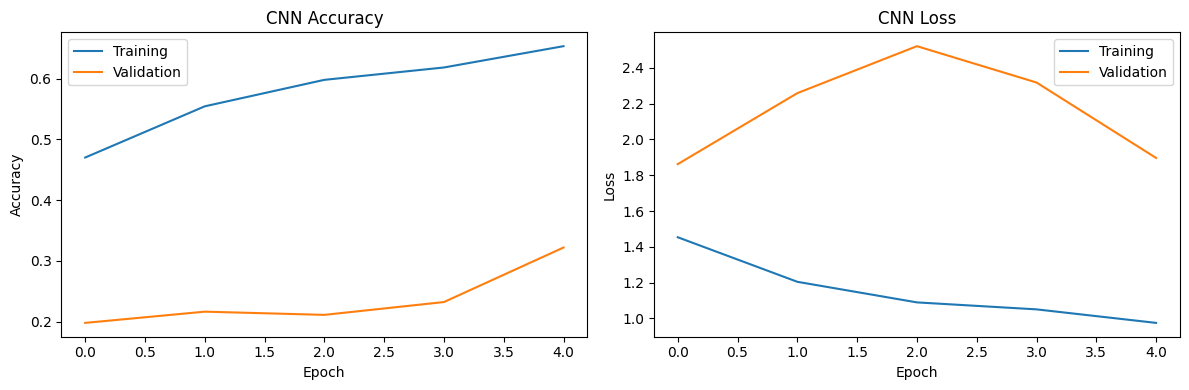

In [6]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 526ms/step - accuracy: 0.2000 - loss: 1.8608
Test Accuracy: 20.00%
Test Loss: 1.8608
              precision    recall  f1-score   support

   cardboard       0.00      0.00      0.00        60
       glass       0.20      1.00      0.33        76
       metal       0.00      0.00      0.00        62
       paper       0.00      0.00      0.00        89
     plastic       0.00      0.00      0.00        73
       trash       0.00      0.00      0.00        20

    accuracy                           0.20       380
   macro avg       0.03      0.17      0.06       380
weighted avg       0.04      0.20      0.07       380



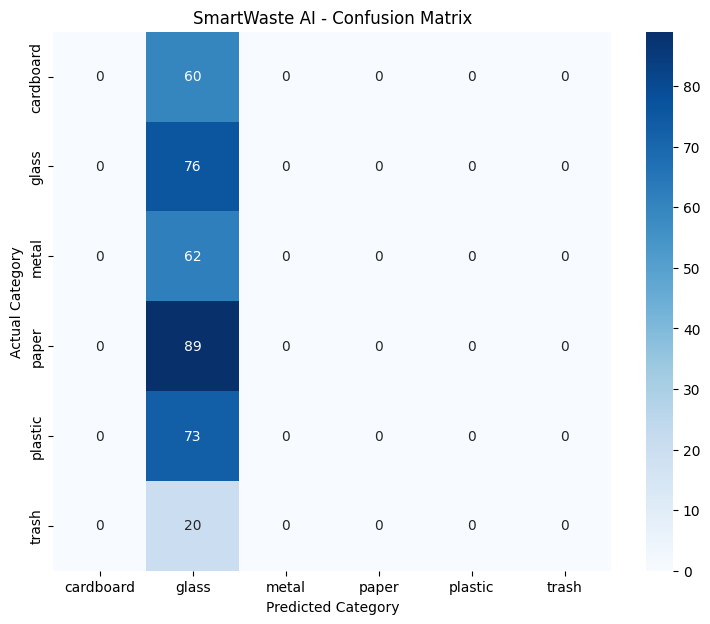

In [7]:

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

y_true = []
y_pred = []

for images, labels_batch in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels_batch.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    cmap="Blues"
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("SmartWaste AI - Confusion Matrix")
plt.show()


In [12]:
# CELL 7: Grad-CAM Explainable AI (FIXED)

import tensorflow as tf
import numpy as np

# Explicitly build/call the CNN model
dummy_input = tf.zeros((1, 128, 128, 3))
_ = model(dummy_input, training=False)

# Create Grad-CAM model
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer("last_conv").output,
        model.outputs[0]
    ]
)

def make_gradcam(image_array):

    image_array = tf.convert_to_tensor(
        image_array, dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        conv_output, predictions = grad_model(
            image_array, training=False
        )

        class_index = tf.argmax(predictions[0])

        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(
        gradients, axis=(0, 1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_output[0] * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / tf.maximum(
        tf.reduce_max(heatmap), 1e-8
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        IMG_SIZE
    ).numpy().squeeze()

    return heatmap

print("Grad-CAM explanation module ready!")

Grad-CAM explanation module ready!


In [11]:

RECYCLING_GUIDE = {
    "cardboard": "Keep dry, flatten boxes and send for paper recycling.",
    "glass": "Separate by glass type and send to an appropriate glass recycler.",
    "metal": "Clean cans and containers before metal recycling.",
    "paper": "Keep paper clean and dry for paper recycling.",
    "plastic": "Check local recycling rules and separate accepted plastics.",
    "trash": "Place in general waste unless a specialized recycling facility accepts it."
}

def predict_waste(image):
    if image is None:
        raise gr.Error("Please upload an image.")

    image = image.convert("RGB")
    original = image.resize(IMG_SIZE)

    arr = np.array(original).astype("float32") / 255.0
    batch = np.expand_dims(arr, axis=0)

    predictions = model.predict(batch, verbose=0)[0]

    index = int(np.argmax(predictions))
    category = CLASSES[index]
    confidence = float(predictions[index])

    result = {
        CLASSES[i]: float(predictions[i])
        for i in range(len(CLASSES))
    }

    heatmap = make_gradcam(batch)

    heatmap_img = Image.fromarray(
        np.uint8(heatmap * 255)
    ).resize(IMG_SIZE)

    import cv2

    heat = cv2.applyColorMap(
        np.array(heatmap_img), cv2.COLORMAP_JET
    )
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)

    original_array = np.array(original)
    overlay = (
        0.55 * original_array +
        0.45 * heat
    ).clip(0, 255).astype("uint8")

    explanation = (
        f"Predicted Category: {category.upper()}\n"
        f"Confidence: {confidence * 100:.2f}%\n\n"
        f"Recycling Guidance:\n{RECYCLING_GUIDE[category]}\n\n"
        "Note: This is an educational model, not a "
        "certified waste-disposal system."
    )

    return result, explanation, Image.fromarray(overlay)

demo = gr.Interface(
    fn=predict_waste,
    inputs=gr.Image(
        type="pil",
        label="Upload Waste Image"
    ),
    outputs=[
        gr.Label(num_top_classes=6, label="CNN Predictions"),
        gr.Textbox(label="AI Recycling Assistant"),
        gr.Image(label="Grad-CAM Explanation")
    ],
    title="♻️ SmartWaste AI",
    description=(
        "CNN-powered intelligent waste classification "
        "with explainable AI and recycling guidance."
    ),
    examples=None
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://602cc045b38438ef8c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [13]:
print("========== SMARTWASTE AI DIAGNOSTICS ==========")

# 1. Check dataset distribution
print("\nDATASET DISTRIBUTION:")

for i, name in enumerate(CLASSES):
    print(name, ":", np.sum(train_labels == i))

# 2. Check model accuracy
train_loss, train_acc = model.evaluate(train_ds, verbose=0)
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print("\nMODEL PERFORMANCE:")
print(f"Training Accuracy: {train_acc*100:.2f}%")
print(f"Validation Accuracy: {val_acc*100:.2f}%")
print(f"Testing Accuracy: {test_acc*100:.2f}%")

# 3. Check prediction distribution
predictions = model.predict(test_ds, verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

print("\nPREDICTION DISTRIBUTION:")

for i, name in enumerate(CLASSES):
    print(name, ":", np.sum(predicted_labels == i))

# 4. Check class mapping
print("\nCLASS MAPPING:")
for i, name in enumerate(CLASSES):
    print(i, "=", name)

print("\n========== DIAGNOSTICS COMPLETE ==========")

========== SMARTWASTE AI DIAGNOSTICS ==========

DATASET DISTRIBUTION:
cardboard : 282
glass : 350
metal : 287
paper : 416
plastic : 337
trash : 96

MODEL PERFORMANCE:
Training Accuracy: 76.30%
Validation Accuracy: 73.35%
Testing Accuracy: 71.32%

PREDICTION DISTRIBUTION:
cardboard : 52
glass : 81
metal : 60
paper : 116
plastic : 65
trash : 6

CLASS MAPPING:
0 = cardboard
1 = glass
2 = metal
3 = paper
4 = plastic
5 = trash

========== DIAGNOSTICS COMPLETE ==========


In [14]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)

class_weights = {
    int(i): float(w)
    for i, w in enumerate(weights)
}

print("CLASS WEIGHTS")

for i, name in enumerate(CLASSES):
    print(name, ":", round(class_weights[i], 3))

CLASS WEIGHTS
cardboard : 1.045
glass : 0.842
metal : 1.027
paper : 0.708
plastic : 0.874
trash : 3.069


In [17]:
# SMARTWASTE AI - IMPROVED TRAINING

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "smartwaste_improved.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_improved = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks
)

print("Improved CNN training completed!")

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 174s 3s/step - accuracy: 0.7347 - loss: 0.7761 - val_accuracy: 0.7573 - val_loss: 0.7048 - learning_rate: 7.8125e-06
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.7404 - loss: 0.7862 - val_accuracy: 0.7388 - val_loss: 0.7091 - learning_rate: 7.8125e-06
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.7330 - loss: 0.8010 - val_accuracy: 0.7546 - val_loss: 0.7060 - learning_rate: 7.8125e-06
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.7262 - loss: 0.7963 - val_accuracy: 0.7546 - val_loss: 0.7002 - learning_rate: 3.9063e-06
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.7398 - loss: 0.7668 - val_accuracy: 0.7546 - val_loss: 0.7011 - learning_rate: 3.9063e-06
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.7364 - loss: 0.7889 - val_accuracy: 0.7441 - val_loss: 0.7021 - learning_rate: 3.9063e-06
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 139s 2s/step - accuracy: 0.7387 

In [16]:
test_loss, test_accuracy = model.evaluate(
    test_ds, verbose=0
)

print(
    f"Improved Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

y_true = []
y_pred = []

for images, labels_batch in test_ds:
    probs = model.predict(images, verbose=0)

    y_true.extend(labels_batch.numpy())
    y_pred.extend(np.argmax(probs, axis=1))

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    zero_division=0
))

Improved Test Accuracy: 70.26%
              precision    recall  f1-score   support

   cardboard       0.91      0.83      0.87        60
       glass       0.82      0.53      0.64        76
       metal       0.59      0.69      0.64        62
       paper       0.81      0.84      0.82        89
     plastic       0.66      0.62      0.64        73
       trash       0.33      0.70      0.45        20

    accuracy                           0.70       380
   macro avg       0.69      0.70      0.68       380
weighted avg       0.74      0.70      0.71       380



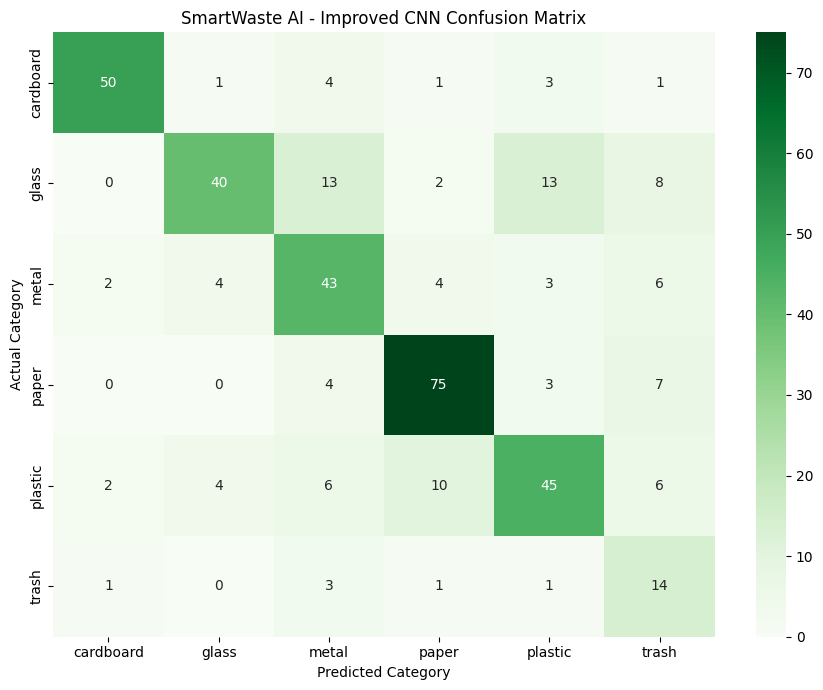

In [18]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("SmartWaste AI - Improved CNN Confusion Matrix")

plt.tight_layout()
plt.show()

FINAL TEST ACCURACY: 72.37 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   cardboard       0.91      0.87      0.89        60
       glass       0.81      0.57      0.67        76
       metal       0.61      0.69      0.65        62
       paper       0.82      0.88      0.85        89
     plastic       0.71      0.62      0.66        73
       trash       0.34      0.70      0.46        20

    accuracy                           0.72       380
   macro avg       0.70      0.72      0.70       380
weighted avg       0.75      0.72      0.73       380



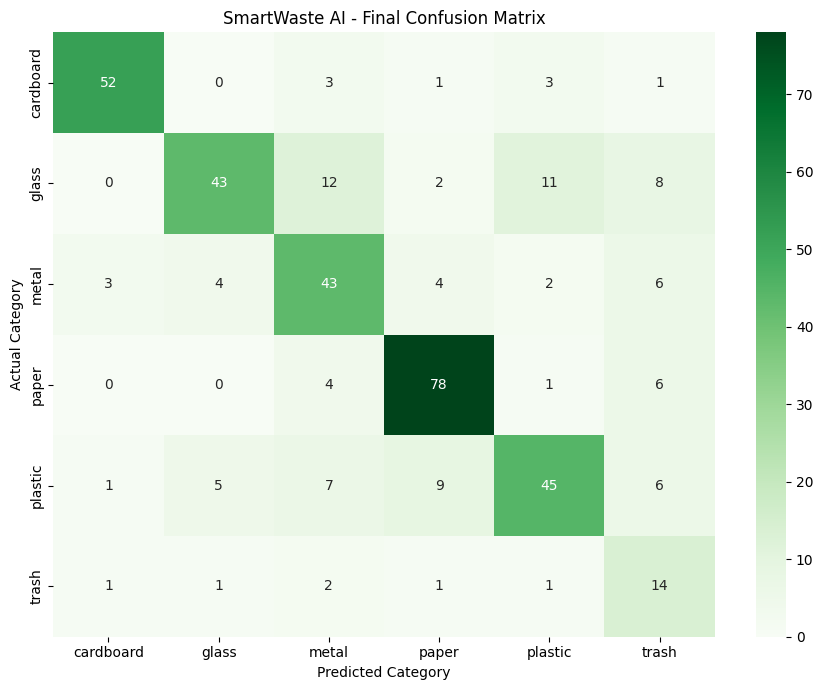

Total test images: 380
Confusion matrix total: 380


In [19]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Generate fresh predictions from the current model
y_true_final = []
y_pred_final = []

for images, labels_batch in test_ds:
    probs = model.predict(images, verbose=0)

    y_true_final.extend(labels_batch.numpy())
    y_pred_final.extend(np.argmax(probs, axis=1))

y_true_final = np.array(y_true_final)
y_pred_final = np.array(y_pred_final)

# Calculate metrics from the same predictions
print("FINAL TEST ACCURACY:",
      round(accuracy_score(y_true_final, y_pred_final)*100, 2), "%")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_true_final,
    y_pred_final,
    labels=list(range(6)),
    target_names=CLASSES,
    zero_division=0
))

# Generate confusion matrix
cm = confusion_matrix(
    y_true_final,
    y_pred_final,
    labels=list(range(6))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("SmartWaste AI - Final Confusion Matrix")
plt.tight_layout()
plt.show()

print("Total test images:", len(y_true_final))
print("Confusion matrix total:", cm.sum())

In [20]:
# CELL 1: MobileNetV2 Dataset Preparation

import tensorflow as tf
import numpy as np
import os

IMG_SIZE_M = (160, 160)
BATCH_SIZE_M = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_mobilenet_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    # Keep pixel values in the 0-255 range.
    # MobileNetV2 preprocessing will happen inside the model.
    image = tf.image.resize(image, IMG_SIZE_M)

    return image, label

def make_mobilenet_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    ds = ds.map(
        load_mobilenet_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        ds = ds.shuffle(
            1000, seed=42, reshuffle_each_iteration=True
        )

    return ds.batch(BATCH_SIZE_M).prefetch(AUTOTUNE)

train_ds_m = make_mobilenet_dataset(
    train_paths, train_labels, True
)

val_ds_m = make_mobilenet_dataset(
    val_paths, val_labels
)

test_ds_m = make_mobilenet_dataset(
    test_paths, test_labels
)

print("MobileNetV2 datasets prepared!")
print("Training:", len(train_paths))
print("Validation:", len(val_paths))
print("Testing:", len(test_paths))

MobileNetV2 datasets prepared!
Training: 1768
Validation: 379
Testing: 380


In [21]:
# CELL 2: Load MobileNetV2

from tensorflow.keras import layers, models

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 pretrained weights loaded!")
print("Base model layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 pretrained weights loaded!
Base model layers: 154


In [23]:
# CELL 3: Build SmartWaste MobileNetV2

inputs = layers.Input(
    shape=(160, 160, 3),
    name="waste_image"
)

augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
], name="augmentation")

x = augmentation(inputs)

# MobileNetV2 expects preprocessing to [-1, 1].
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Extract pretrained visual features.
feature_maps = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(feature_maps)
x = layers.Dropout(0.35)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    6,
    activation="softmax",
    name="waste_predictions"
)(x)

mobilenet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="SmartWaste_MobileNetV2"
)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

Model: "SmartWaste_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ waste_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ waste_predictions (Dense)       │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [24]:
# CELL 4: Stage 1 Training

callbacks_m = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "smartwaste_mobilenet_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_m1 = mobilenet_model.fit(
    train_ds_m,
    validation_data=val_ds_m,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks_m
)

print("MobileNetV2 classification head training completed!")

Epoch 1/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.5373 - loss: 1.3099 - val_accuracy: 0.7309 - val_loss: 0.7110 - learning_rate: 0.0010
Epoch 2/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.7149 - loss: 0.7745 - val_accuracy: 0.7757 - val_loss: 0.6068 - learning_rate: 0.0010
Epoch 3/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.7574 - loss: 0.6693 - val_accuracy: 0.7995 - val_loss: 0.5870 - learning_rate: 0.0010
Epoch 4/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.7952 - loss: 0.5923 - val_accuracy: 0.8100 - val_loss: 0.5638 - learning_rate: 0.0010
Epoch 5/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.7947 - loss: 0.5493 - val_accuracy: 0.8153 - val_loss: 0.5444 - learning_rate: 0.0010
Epoch 6/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.7947 - loss: 0.5203 - val_accuracy: 0.8127 - val_loss: 0.6380 - learning_rate: 0.0010
Epoch 7/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 58s 996ms/step - accuracy: 0.8184 - loss: 0.4757 - val_accuracy: 0.83

In [26]:
# CELL 5: Stage 2 Fine-Tuning

base_model.trainable = True

# Freeze all but the last 30 layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_m2 = mobilenet_model.fit(
    train_ds_m,
    validation_data=val_ds_m,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks_m
)

print("MobileNetV2 fine-tuning completed!")

Epoch 1/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.8857 - loss: 0.2949 - val_accuracy: 0.8443 - val_loss: 0.4611 - learning_rate: 1.0000e-05
Epoch 2/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - accuracy: 0.8920 - loss: 0.2803 - val_accuracy: 0.8575 - val_loss: 0.4692 - learning_rate: 1.0000e-05
Epoch 3/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9010 - loss: 0.2671 - val_accuracy: 0.8496 - val_loss: 0.4698 - learning_rate: 5.0000e-06
MobileNetV2 fine-tuning completed!


12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 571ms/step - accuracy: 0.8868 - loss: 0.3731

SMARTWASTE AI - MOBILENETV2 RESULTS
------------------------------------
Test Accuracy: 88.68%
Test Loss: 0.3731

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   cardboard       0.89      0.93      0.91        60
       glass       0.84      0.87      0.85        76
       metal       0.92      0.92      0.92        62
       paper       0.93      0.93      0.93        89
     plastic       0.88      0.81      0.84        73
       trash       0.80      0.80      0.80        20

    accuracy                           0.89       380
   macro avg       0.88      0.88      0.88       380
weighted avg       0.89      0.89      0.89       380



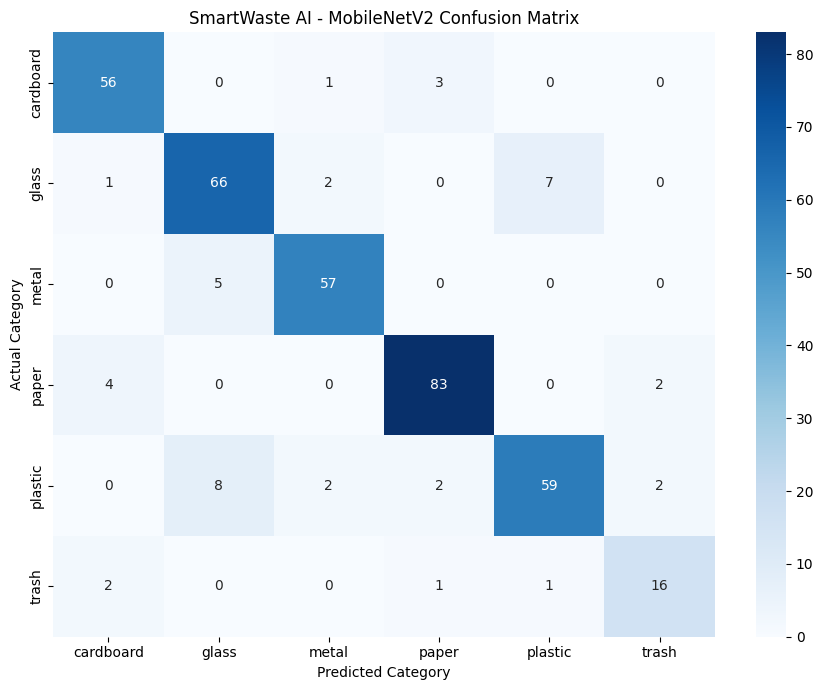

In [27]:
# CELL 6: Final MobileNetV2 Evaluation

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns

test_loss_m, test_accuracy_m = mobilenet_model.evaluate(
    test_ds_m,
    verbose=1
)

y_true_m = []
y_pred_m = []

for images, labels_batch in test_ds_m:
    probabilities = mobilenet_model.predict(
        images, verbose=0
    )

    y_true_m.extend(labels_batch.numpy())
    y_pred_m.extend(np.argmax(probabilities, axis=1))

y_true_m = np.array(y_true_m)
y_pred_m = np.array(y_pred_m)

print("\nSMARTWASTE AI - MOBILENETV2 RESULTS")
print("------------------------------------")

print(
    f"Test Accuracy: "
    f"{accuracy_score(y_true_m, y_pred_m)*100:.2f}%"
)

print(f"Test Loss: {test_loss_m:.4f}")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_true_m,
    y_pred_m,
    labels=list(range(6)),
    target_names=CLASSES,
    zero_division=0
))

cm_m = confusion_matrix(
    y_true_m,
    y_pred_m,
    labels=list(range(6))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_m,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("SmartWaste AI - MobileNetV2 Confusion Matrix")

plt.tight_layout()
plt.show()

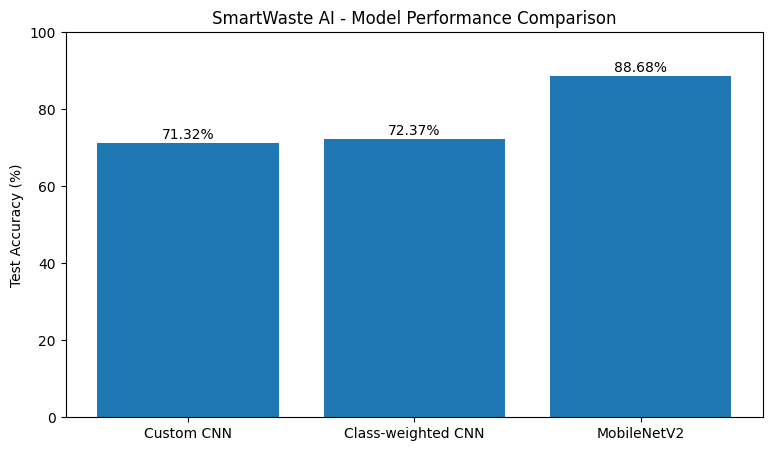

MODEL COMPARISON
Custom CNN: 71.32%
Class-weighted CNN: 72.37%
MobileNetV2: 88.68%


In [28]:
# CELL 7: Model Comparison

custom_cnn_accuracy = 72.37
mobilenet_accuracy = accuracy_score(
    y_true_m, y_pred_m
) * 100

models_names = [
    "Custom CNN",
    "Class-weighted CNN",
    "MobileNetV2"
]

accuracies = [
    71.32,
    custom_cnn_accuracy,
    mobilenet_accuracy
]

plt.figure(figsize=(9, 5))

bars = plt.bar(models_names, accuracies)

plt.ylim(0, 100)
plt.ylabel("Test Accuracy (%)")
plt.title("SmartWaste AI - Model Performance Comparison")

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

print("MODEL COMPARISON")
for name, score in zip(models_names, accuracies):
    print(f"{name}: {score:.2f}%")

In [29]:
# CELL 8: MobileNetV2 Grad-CAM

grad_model_m = tf.keras.Model(
    inputs=inputs,
    outputs=[feature_maps, outputs]
)

def make_gradcam_m(image_array):

    image_array = tf.convert_to_tensor(
        image_array,
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        conv_output, predictions = grad_model_m(
            image_array,
            training=False
        )

        class_index = tf.argmax(predictions[0])

        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_output[0] * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / tf.maximum(
        tf.reduce_max(heatmap),
        1e-8
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        IMG_SIZE_M
    ).numpy().squeeze()

    return heatmap

print("MobileNetV2 Grad-CAM ready!")

MobileNetV2 Grad-CAM ready!


In [30]:
# CELL 9: SmartWaste AI 3.0 - Gradio Application

import gradio as gr
import cv2
from PIL import Image

RECYCLING_GUIDE = {
    "cardboard": "Keep dry, flatten boxes and send for paper recycling.",
    "glass": "Separate glass items and send to an appropriate recycler.",
    "metal": "Clean metal cans and containers before recycling.",
    "paper": "Keep paper clean and dry for paper recycling.",
    "plastic": "Check local recycling rules and separate accepted plastics.",
    "trash": "Dispose through the appropriate general waste facility."
}

def predict_mobilenet(image):

    if image is None:
        raise gr.Error("Please upload an image.")

    original = image.convert("RGB").resize(IMG_SIZE_M)

    image_array = np.array(original).astype("float32")

    batch = np.expand_dims(image_array, axis=0)

    probabilities = mobilenet_model.predict(
        batch, verbose=0
    )[0]

    top_indices = np.argsort(probabilities)[::-1]

    results = {
        CLASSES[i]: float(probabilities[i])
        for i in top_indices
    }

    index = int(np.argmax(probabilities))
    category = CLASSES[index]
    confidence = float(probabilities[index])

    heatmap = make_gradcam_m(batch)

    heatmap = cv2.resize(
        heatmap,
        IMG_SIZE_M
    )

    heat_color = cv2.applyColorMap(
        np.uint8(255 * heatmap),
        cv2.COLORMAP_JET
    )

    heat_color = cv2.cvtColor(
        heat_color,
        cv2.COLOR_BGR2RGB
    )

    original_array = np.array(original)

    overlay = cv2.addWeighted(
        original_array,
        0.55,
        heat_color,
        0.45,
        0
    )

    status = (
        "Please review this prediction."
        if confidence < 0.65
        else "Prediction generated successfully."
    )

    explanation = (
        f"Predicted Category: {category.upper()}\n"
        f"Confidence: {confidence*100:.2f}%\n"
        f"Status: {status}\n\n"
        f"Recycling Guidance:\n"
        f"{RECYCLING_GUIDE[category]}\n\n"
        "Note: This is an educational classification model."
    )

    return (
        results,
        explanation,
        Image.fromarray(overlay)
    )

demo_mobilenet = gr.Interface(
    fn=predict_mobilenet,
    inputs=gr.Image(
        type="pil",
        label="Upload Waste Image"
    ),
    outputs=[
        gr.Label(
            num_top_classes=6,
            label="MobileNetV2 Predictions"
        ),
        gr.Textbox(
            label="AI Recycling Assistant"
        ),
        gr.Image(
            label="Grad-CAM Explanation"
        )
    ],
    title="♻️ SmartWaste AI 3.0",
    description=(
        "Transfer-learning-powered waste classification "
        "with MobileNetV2 and explainable AI."
    )
)

demo_mobilenet.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://17589e85619ccf4da6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
mobilenet_model.save(
    "/content/SmartWaste_AI_MobileNetV2.keras"
)

print("Model saved successfully!")